# Mask R-CNN - Train on JuniperMapper

This notebook shows how to train Mask R-CNN on [JuniperMapper dataset](https://zenodo.org/records/10058715).

In [1]:
from matplotlib import pyplot as plt
import os
import sys
import math
import numpy as np

from keras.callbacks import CSVLogger
from keras.callbacks import ModelCheckpoint

sys.path.append(os.path.join(os.path.dirname(os.getcwd()), 'bin'))
import mrcnn.model as modellib
from mrcnn import utils # type: ignore
from mrcnn import visualize
from shrubs import ShrubConfig, ShrubDataset
from shrubs import WarmupCosineScheduler

Using TensorFlow backend.


## Configurations

In [2]:
%matplotlib inline 

ROOT = os.path.join(os.path.dirname(os.getcwd()))

# Directory to save logs and trained model
MODEL_DIR = os.path.join(ROOT, "data/logs")

# Directory with train data
TRAIN_DIR = os.path.join(
    ROOT,
    "data/JuniperMapper", "Photo_Interpretation_Data"
)

# Local path to store the COCO trained weights
COCO_MODEL_PATH = os.path.join(ROOT, "data/logs/mask_rcnn_coco.h5")
# Download COCO trained weights from Releases if needed
if not os.path.exists(COCO_MODEL_PATH):
    utils.download_trained_weights(COCO_MODEL_PATH)

In [3]:
config = ShrubConfig()
config.display()


Configurations:
BACKBONE                       resnet101
BACKBONE_STRIDES               [4, 8, 16, 32, 64]
BATCH_SIZE                     2
BBOX_STD_DEV                   [0.1 0.1 0.2 0.2]
COMPUTE_BACKBONE_SHAPE         None
DETECTION_MAX_INSTANCES        256
DETECTION_MIN_CONFIDENCE       0.7
DETECTION_NMS_THRESHOLD        0.3
FPN_CLASSIF_FC_LAYERS_SIZE     1024
GPU_COUNT                      1
GRADIENT_CLIP_NORM             5.0
IMAGES_PER_GPU                 2
IMAGE_CHANNEL_COUNT            3
IMAGE_MAX_DIM                  448
IMAGE_META_SIZE                14
IMAGE_MIN_DIM                  448
IMAGE_MIN_SCALE                0
IMAGE_RESIZE_MODE              square
IMAGE_SHAPE                    [448 448   3]
LEARNING_MOMENTUM              0.9
LEARNING_RATE                  0.0025
LOSS_WEIGHTS                   {'rpn_class_loss': 1.0, 'rpn_bbox_loss': 1.0, 'mrcnn_class_loss': 1.0, 'mrcnn_bbox_loss': 1.0, 'mrcnn_mask_loss': 1.0}
MASK_POOL_SIZE                 14
MASK_SHAPE            

Create a best-model checkpoint.

In [4]:
best_model_path = os.path.join(
    MODEL_DIR,
    "best_mask_rcnn_weights.h5",
)

best_checkpoint = ModelCheckpoint(
    filepath=best_model_path,
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    save_weights_only=True,
    verbose=1,
)

Store the loss and other metrics produced during training phase into a CSV file.

In [5]:
csv_logger = CSVLogger(
    filename=os.path.join(MODEL_DIR, "training_metrics.csv"),
    separator=",",
    append=False
)

## Notebook Preferences

In [6]:
def get_ax(rows=1, cols=1, size=8):
    """Return a Matplotlib Axes array to be used in
    all visualizations in the notebook. Provide a
    central point to control graph sizes.
    
    Change the default size attribute to control the size
    of rendered images
    """
    _, ax = plt.subplots(rows, cols, figsize=(size*cols, size*rows))
    return ax

## Dataset

In [7]:
# Training dataset
dataset_train = ShrubDataset()
dataset_train.load_dataset(
    os.path.join(TRAIN_DIR, "Train", "Images"),
    os.path.join(TRAIN_DIR, "Train", "masks_points.json")
)
dataset_train.prepare()

# Validation dataset
dataset_val = ShrubDataset()
dataset_val.load_dataset(
    os.path.join(TRAIN_DIR, "Val", "Images"),
    os.path.join(TRAIN_DIR, "Val", "masks_points.json")
)
dataset_val.prepare()

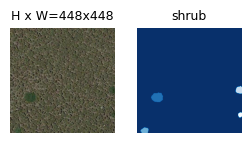

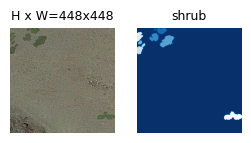

In [8]:
# Load and display random samples
image_ids = np.random.choice(dataset_train.image_ids, 2)
for image_id in image_ids:
    image = dataset_train.load_image(image_id)
    mask, class_ids = dataset_train.load_mask(image_id)
    visualize.display_top_masks(
        image,
        mask,
        class_ids,
        dataset_train.class_names,
        limit=1,
        figsize=(3,3)
    )

Update the config parameter `VALIDATION_STEPS`, which is the number of validation batches, not the number of validation images.

Note that this approach has one caveat. The generator yields only when it has accumulated a complete batch. It does not normally produce a smaller final batch. With 67 images and batch size 2, the 34th batch can contain one repeated image from the next dataset cycle.

Consequently, the following line processes 68 image samples, with one validation image potentially appearing twice. We have assumed that.

In [9]:
# Set the number of validation batches
VALIDATION_STEPS = math.ceil(len(dataset_val.image_ids) / config.BATCH_SIZE)
config.VALIDATION_STEPS = VALIDATION_STEPS

## Create Model

In [10]:
# Create model in training mode
model = modellib.MaskRCNN(
    mode="training",
    config=config,
    model_dir=MODEL_DIR
)

In [11]:
# Start with weights from COCO
# Also available: imagenet or last
init_with = "coco"

if init_with == "imagenet":
    model.load_weights(model.get_imagenet_weights(), by_name=True)
elif init_with == "coco":
    # Load weights trained on MS COCO, but skip layers that
    # are different due to the different number of classes
    # See README for instructions to download the COCO weights
    excluded_layers = [
        "mrcnn_class_logits",
        "mrcnn_bbox_fc", 
        "mrcnn_bbox",
        "mrcnn_mask"
    ]

    model.load_weights(COCO_MODEL_PATH, by_name=True, exclude=excluded_layers)

elif init_with == "last":
    # Load the last model you trained and continue training
    model.load_weights(model.find_last(), by_name=True)

Create the scheduler to define a custom learning rate scheduler.

> WarmupCosine (2000 iterations, factor of 10)

In [12]:
warmup_cosine = WarmupCosineScheduler(
    base_lr=0.0025,
    warmup_iterations=2000,
    total_iterations=4000,
    warmup_factor=10.0,
    minimum_lr=0.0,
    verbose=1,
)

## Training

Perform transfer learning to fine tunning only the heads. The backbone layers are freezing and training only the randomly initialized layers (i.e. the ones that we didn't use pre-trained weights from MS COCO). To train only the head layers, pass `layers='heads'` to the `train()` function.

In [13]:
print("Model directory:", model.model_dir)
print("Log directory:", model.log_dir)
print("Checkpoint path:", model.checkpoint_path)

Model directory: c:\IRANZO\shrubs-segmentation\data/logs
Log directory: c:\IRANZO\shrubs-segmentation\data/logs\shrubs_cfg
Checkpoint path: c:\IRANZO\shrubs-segmentation\data/logs\shrubs_cfg\mask_rcnn_shrubs_cfg_{epoch:04d}.h5


In [14]:
# Train the head branches
# Passing layers="heads" freezes all layers except the head
# layers. You can also pass a regular expression to select
# which layers to train by name pattern.
model.train(
    dataset_train,
    dataset_val, 
    learning_rate=config.LEARNING_RATE, 
    epochs=config.TOTAL_EPOCHS, 
    layers='heads',
    custom_callbacks=[
        warmup_cosine,
        best_checkpoint,
        csv_logger
    ],
    validation_freq=10,
    save_default_checkpoints=False
)


Starting at epoch 0. LR=0.0025

Checkpoint Path: c:\IRANZO\shrubs-segmentation\data/logs\shrubs_cfg\mask_rcnn_shrubs_cfg_{epoch:04d}.h5
Selecting layers to train
fpn_c5p5               (Conv2D)
fpn_c4p4               (Conv2D)
fpn_c3p3               (Conv2D)
fpn_c2p2               (Conv2D)
fpn_p5                 (Conv2D)
fpn_p2                 (Conv2D)
fpn_p3                 (Conv2D)
fpn_p4                 (Conv2D)
In model:  rpn_model
    rpn_conv_shared        (Conv2D)
    rpn_class_raw          (Conv2D)
    rpn_bbox_pred          (Conv2D)
mrcnn_mask_conv1       (TimeDistributed)
mrcnn_mask_bn1         (TimeDistributed)
mrcnn_mask_conv2       (TimeDistributed)
mrcnn_mask_bn2         (TimeDistributed)
mrcnn_class_conv1      (TimeDistributed)
mrcnn_class_bn1        (TimeDistributed)
mrcnn_mask_conv3       (TimeDistributed)
mrcnn_mask_bn3         (TimeDistributed)
mrcnn_class_conv2      (TimeDistributed)
mrcnn_class_bn2        (TimeDistributed)
mrcnn_mask_conv4       (TimeDistributed)
m

c:\Users\usuario\miniforge3\envs\mrcnn_tf2\lib\site-packages\tensorflow_core\python\framework\indexed_slices.py:424: UserWarning: Converting sparse IndexedSlices to a dense Tensor of unknown shape. This may consume a large amount of memory.
  "Converting sparse IndexedSlices to a dense Tensor of unknown shape. "
c:\Users\usuario\miniforge3\envs\mrcnn_tf2\lib\site-packages\tensorflow_core\python\framework\indexed_slices.py:424: UserWarning: Converting sparse IndexedSlices to a dense Tensor of unknown shape. This may consume a large amount of memory.
  "Converting sparse IndexedSlices to a dense Tensor of unknown shape. "
c:\Users\usuario\miniforge3\envs\mrcnn_tf2\lib\site-packages\tensorflow_core\python\framework\indexed_slices.py:424: UserWarning: Converting sparse IndexedSlices to a dense Tensor of unknown shape. This may consume a large amount of memory.
  "Converting sparse IndexedSlices to a dense Tensor of unknown shape. "


Epoch 1/40

Iteration 0: learning rate = 0.00025000
100/100 [==============================] - 1214s 12s/step - loss: 2.4270
Epoch 2/40


c:\Users\usuario\miniforge3\envs\mrcnn_tf2\lib\site-packages\keras\callbacks\callbacks.py:707: RuntimeWarning: Can save best model only with val_loss available, skipping.
  'skipping.' % (self.monitor), RuntimeWarning)



Iteration 100: learning rate = 0.00036250
100/100 [==============================] - 1207s 12s/step - loss: 1.6341
Epoch 3/40


...


Iteration 700: learning rate = 0.00103750
100/100 [==============================] - 1178s 12s/step - loss: 1.2663
Epoch 9/40


c:\Users\usuario\miniforge3\envs\mrcnn_tf2\lib\site-packages\keras\callbacks\callbacks.py:707: RuntimeWarning: Can save best model only with val_loss available, skipping.
  'skipping.' % (self.monitor), RuntimeWarning)



Iteration 800: learning rate = 0.00115000
100/100 [==============================] - 1180s 12s/step - loss: 1.2185
Epoch 10/40


c:\Users\usuario\miniforge3\envs\mrcnn_tf2\lib\site-packages\keras\callbacks\callbacks.py:707: RuntimeWarning: Can save best model only with val_loss available, skipping.
  'skipping.' % (self.monitor), RuntimeWarning)



Iteration 900: learning rate = 0.00126250
100/100 [==============================] - 1244s 12s/step - loss: 1.2626 - val_loss: 1.4153

Epoch 00010: val_loss improved from inf to 1.41535, saving model to c:\IRANZO\shrubs-segmentation\data/logs\best_mask_rcnn_weights.h5
Epoch 11/40

Iteration 1000: learning rate = 0.00137500
100/100 [==============================] - 1182s 12s/step - loss: 1.1991 - val_loss: 1.4153

Epoch 00011: val_loss did not improve from 1.41535
Epoch 12/40

Iteration 1100: learning rate = 0.00148750
100/100 [==============================] - 1183s 12s/step - loss: 1.2071 - val_loss: 1.4153

Epoch 00012: val_loss did not improve from 1.41535
Epoch 13/40

Iteration 1200: learning rate = 0.00160000
100/100 [==============================] - 1186s 12s/step - loss: 1.0985 - val_loss: 1.4153

Epoch 00013: val_loss did not improve from 1.41535
Epoch 14/40

Iteration 1300: learning rate = 0.00171250
100/100 [==============================] - 1190s 12s/step - loss: 1.1270 -